**DATA LOADING USING GIVEN CODE**

In [1]:
pip install ucimlrepo

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [1]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
heart_disease = fetch_ucirepo(id=45) 
  
# data (as pandas dataframes) 
X = heart_disease.data.features 
y = heart_disease.data.targets 
  
# metadata 
print(heart_disease.metadata) 
  
# variable information 
print(heart_disease.variables) 


{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

In [2]:
#showcasing X
X

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,1,110,264,0,0,132,0,1.2,2,0.0,7.0
299,68,1,4,144,193,1,0,141,0,3.4,2,2.0,7.0
300,57,1,4,130,131,0,0,115,1,1.2,2,1.0,7.0
301,57,0,2,130,236,0,2,174,0,0.0,2,1.0,3.0


In [3]:
#showcasing y
y

,num
0,0
1,2
2,1
3,0
4,0
...,...
298,1
299,2
300,3
301,1


**EDA & DATA PREPROCESSING**

In [4]:
#checking maximum value of target that has to be converted to binary
y.max()

num    4
dtype: int64

In [5]:
#converting y(target) to binary
y_binary = y.replace({1:1, 2:1, 3:1, 4:1})
y_binary

,num
0,0
1,1
2,1
3,0
4,0
...,...
298,1
299,1
300,1
301,1


In [6]:
X.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000


In [7]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
dtypes: float64(3), int64(10)
memory usage: 30.9 KB


In [8]:
# Check for missing values
X.isna().sum()

# Impute missing values with column median
print(X.median())
X = X.fillna(X.median())
X

age          56.0
sex           1.0
cp            3.0
trestbps    130.0
chol        241.0
fbs           0.0
restecg       1.0
thalach     153.0
exang         0.0
oldpeak       0.8
slope         2.0
ca            0.0
thal          3.0
dtype: float64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,1,110,264,0,0,132,0,1.2,2,0.0,7.0
299,68,1,4,144,193,1,0,141,0,3.4,2,2.0,7.0
300,57,1,4,130,131,0,0,115,1,1.2,2,1.0,7.0
301,57,0,2,130,236,0,2,174,0,0.0,2,1.0,3.0


In [9]:
#Normalize using StandardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled)

[[ 0.94872647  0.68620244 -2.25177456 ...  2.27457861 -0.71113139
   0.66000414]
 [ 1.39200191  0.68620244  0.87798549 ...  0.64911323  2.5048807
  -0.89023814]
 [ 1.39200191  0.68620244  0.87798549 ...  0.64911323  1.43287667
   1.17675157]
 ...
 [ 0.28381332  0.68620244  0.87798549 ...  0.64911323  0.36087264
   1.17675157]
 [ 0.28381332 -1.4572959  -1.20852121 ...  0.64911323  0.36087264
  -0.89023814]
 [-1.82174501  0.68620244 -0.16526786 ... -0.97635214 -0.71113139
  -0.89023814]]


In [10]:
#Converting normalized into table using pandas
import pandas as pd

X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
X_scaled_df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,0.948726,0.686202,-2.251775,0.757525,-0.264900,2.394438,1.016684,0.017197,-0.696631,1.087338,2.274579,-0.711131,0.660004
1,1.392002,0.686202,0.877985,1.611220,0.760415,-0.417635,1.016684,-1.821905,1.435481,0.397182,0.649113,2.504881,-0.890238
2,1.392002,0.686202,0.877985,-0.665300,-0.342283,-0.417635,1.016684,-0.902354,1.435481,1.346147,0.649113,1.432877,1.176752
3,-1.932564,0.686202,-0.165268,-0.096170,0.063974,-0.417635,-0.996749,1.637359,-0.696631,2.122573,2.274579,-0.711131,-0.890238
4,-1.489288,-1.457296,-1.208521,-0.096170,-0.825922,-0.417635,1.016684,0.980537,-0.696631,0.310912,-0.976352,-0.711131,-0.890238
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,-1.046013,0.686202,-2.251775,-1.234430,0.334813,-0.417635,-0.996749,-0.770990,-0.696631,0.138373,0.649113,-0.711131,1.176752
299,1.502821,0.686202,0.877985,0.700612,-1.038723,2.394438,-0.996749,-0.376896,-0.696631,2.036303,0.649113,1.432877,1.176752
300,0.283813,0.686202,0.877985,-0.096170,-2.238149,-0.417635,-0.996749,-1.515388,1.435481,0.138373,0.649113,0.360873,1.176752
301,0.283813,-1.457296,-1.208521,-0.096170,-0.206864,-0.417635,1.016684,1.068113,-0.696631,-0.896862,0.649113,0.360873,-0.890238


**HEART DISEASE PREDICTION**

In [11]:
#Spliting dataset into train and test
from sklearn.model_selection import train_test_split

X_train_heart, X_test_heart, y_train_heart, y_test_heart = train_test_split(
    X_scaled_df, y_binary, test_size=0.2, stratify=y_binary
)

In [12]:
#Logiestic regression model
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression()
lr_model.fit(X_train_heart, y_train_heart)

C:\Users\athar\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [13]:
#Random Forset Classifier
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier()
rf_model.fit(X_train_heart, y_train_heart)

C:\Users\athar\AppData\Roaming\Python\Python311\site-packages\sklearn\base.py:1363: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [14]:
#Evaluate model
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def evaluate_model(model, name):
    y_pred_heart = model.predict(X_test_heart)
    print(f"\n{name} Evaluation:")
    print("Accuracy:", accuracy_score(y_test_heart, y_pred_heart))
    print("Precision:", precision_score(y_test_heart, y_pred_heart))
    print("Recall:", recall_score(y_test_heart, y_pred_heart))
    print("F1 Score:", f1_score(y_test_heart, y_pred_heart))
    print("Confusion Matrix:\n", confusion_matrix(y_test_heart, y_pred_heart))

In [15]:
#Evaluation output
evaluate_model(lr_model, "Logistic Regression")
evaluate_model(rf_model, "Random Forest")


Logistic Regression Evaluation:
Accuracy: 0.8360655737704918
Precision: 0.8214285714285714
Recall: 0.8214285714285714
F1 Score: 0.8214285714285714
Confusion Matrix:
 [[28  5]
 [ 5 23]]

Random Forest Evaluation:
Accuracy: 0.819672131147541
Precision: 0.7931034482758621
Recall: 0.8214285714285714
F1 Score: 0.8070175438596491
Confusion Matrix:
 [[27  6]
 [ 5 23]]


**Cholesterol Level Prediction**

In [18]:
#Taking scaled data for all except "chol"
X_chol = X_scaled_df.drop(columns=["chol"])
y_chol = X["chol"]  # use original unscaled chol

In [46]:
#Splitting data into train and test
X_train_chol, X_test_chol, y_train_chol, y_test_chol = train_test_split(
    X_chol, y_chol, test_size=0.2
)

In [47]:
#Linear Regression
from sklearn.linear_model import LinearRegression

lr_chol = LinearRegression()
lr_chol.fit(X_train_chol, y_train_chol)

print("R² Score on Test Set:", lr_chol.score(X_test_chol, y_test_chol))

R² Score on Test Set: 0.12076318820370457


In [48]:
# Correlation matrix on original (non-scaled) data
corr_matrix = X.corr()
print(corr_matrix)

               age       sex        cp  trestbps      chol       fbs  \
age       1.000000 -0.097542  0.104139  0.284946  0.208950  0.118530   
sex      -0.097542  1.000000  0.010084 -0.064456 -0.199915  0.047862   
cp        0.104139  0.010084  1.000000 -0.036077  0.072319 -0.039975   
trestbps  0.284946 -0.064456 -0.036077  1.000000  0.130120  0.175340   
chol      0.208950 -0.199915  0.072319  0.130120  1.000000  0.009841   
fbs       0.118530  0.047862 -0.039975  0.175340  0.009841  1.000000   
restecg   0.148868  0.021647  0.067505  0.146560  0.171043  0.069564   
thalach  -0.393806 -0.048663 -0.334422 -0.045351 -0.003432 -0.007854   
exang     0.091661  0.146201  0.384060  0.064762  0.061310  0.025665   
oldpeak   0.203805  0.102173  0.202277  0.189171  0.046564  0.005747   
slope     0.161770  0.037533  0.152050  0.117382 -0.004062  0.059894   
ca        0.365323  0.086048  0.233117  0.097528  0.123726  0.140764   
thal      0.128303  0.380581  0.262089  0.134424  0.018351  0.06

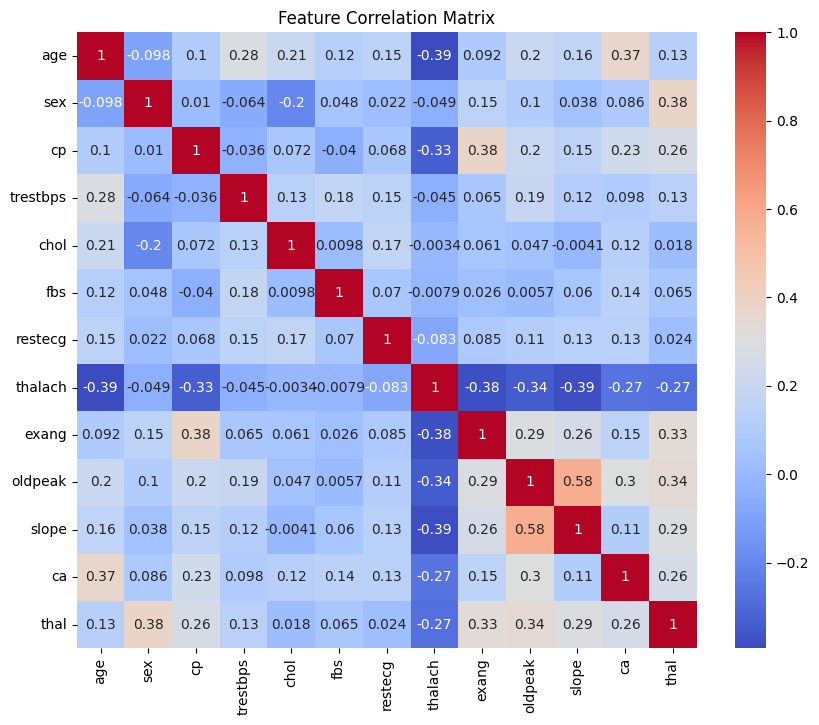

In [49]:
#Visualsing heatmap
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.title("Feature Correlation Matrix")
plt.show()

<br>Age shows a moderate positive correlation of 0.21 with chol. This implies that cholesterol levels tend to increase slightly with age.</br>
<br>None of the features show a strong linear correlation (e.g., > 0.5 or < -0.5) with serum cholesterol. This suggests that cholesterol is not linearly predictable from any single feature alone and may require multivariate relationships captured better by a regression model.</br>
    

**Principal Component Analysis**

In [62]:
#Implementing PCA with 95% variance
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled_df)

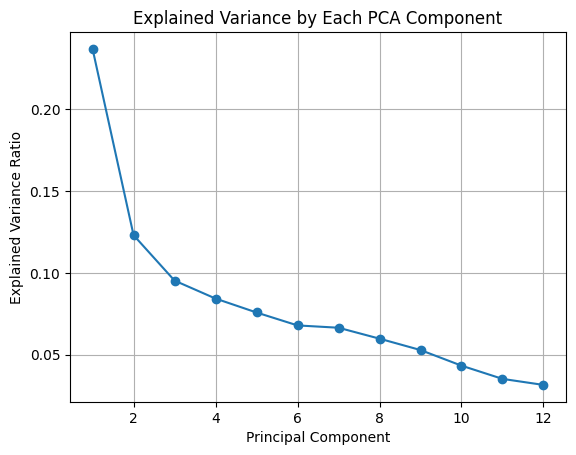

In [63]:
#Plotting explained variance
plt.plot(range(1, len(pca.explained_variance_ratio_)+1), pca.explained_variance_ratio_, marker='o')
plt.title("Explained Variance by Each PCA Component")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.grid()
plt.show()

In [64]:
#Printing original and reduced shape
print("Original Shape:", X_scaled_df.shape)
print("Reduced Shape:", X_pca.shape)

Original Shape: (303, 13)
Reduced Shape: (303, 12)


**Grouping Patients based on Health Profiles**

In [66]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [80]:
#Kmeans
inertia = []
sil_scores = []
K_range = range(2, 15)

for k in K_range:
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(X_pca)
    inertia.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_pca, kmeans.labels_))

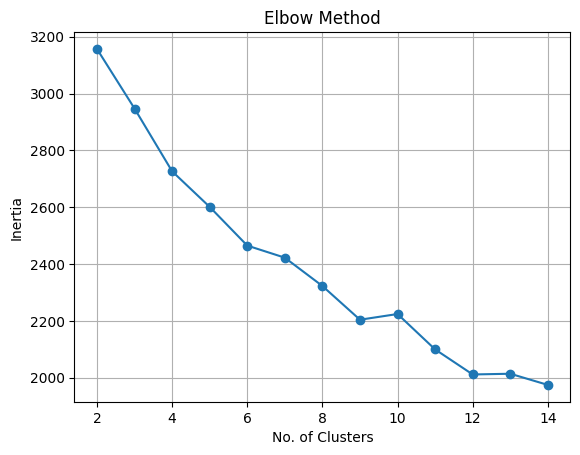

In [81]:
# Elbow plot
plt.plot(K_range, inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("No. of Clusters")
plt.ylabel("Inertia")
plt.grid()
plt.show()

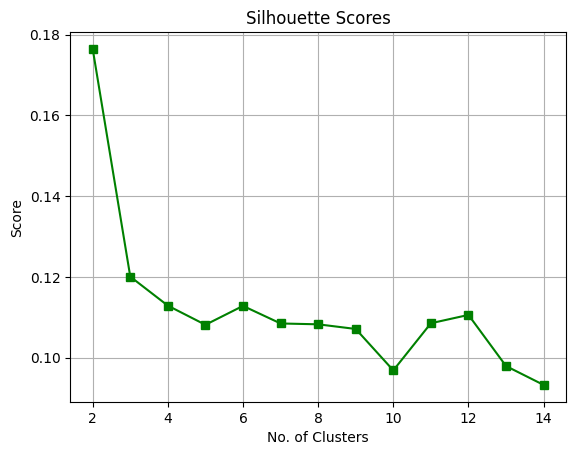

In [82]:
# Silhouette scores plot
plt.plot(K_range, sil_scores, marker='s', color='green')
plt.title("Silhouette Scores")
plt.xlabel("No. of Clusters")
plt.ylabel("Score")
plt.grid()
plt.show()

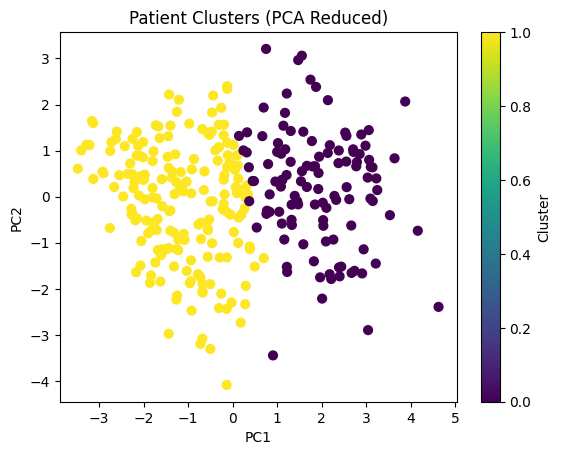

In [86]:
optimal_k = 2  # use the best k found above
kmeans_final = KMeans(n_clusters=optimal_k)
labels = kmeans_final.fit_predict(X_pca)

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis', s=40)
plt.title("Patient Clusters (PCA Reduced)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(label="Cluster")
plt.show()

### 🔍 Choosing the Optimal Number of Clusters

We evaluated both the Elbow Method and Silhouette Scores to determine the ideal number of clusters:

- **Elbow Method** suggests `k=3` as the point where inertia begins to flatten.
- **Silhouette Score** is **highest at `k=2`**, which means that when data is divided into two clusters, the cohesion and separation are strongest.

#### ✅ Final Choice:
We choose **`k=2`** for clustering, as it offers the best silhouette score and produces a simple, interpretable division — potentially grouping patients into two broad health profiles.